# 13 — Yellowstone visitation: EDA, SARIMA baseline (Q0) and forecasting (Q4)

**Person 3, human side of the project.** Data: NPS IRMA *Recreation Visits by Month*,
cleaned by `scripts/build_visitation_data.py` into `data/processed/yell_visits_monthly.csv`.

We work with **log visits** throughout: July is ~40–100× November, and logs turn the
multiplicative seasonal swing into an additive one.

Outputs: figures in `reports/figures/`, tables in `reports/tables/`, and
`reports/tables/q0_sarima_spec.json` (the noise model reused in notebook 14).

In [1]:
import json, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")  # statsmodels convergence/frequency chatter
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

v = pd.read_csv(ROOT / "data/processed/yell_visits_monthly.csv", parse_dates=["Date"], index_col="Date")
v = v[v.Preliminary == 0].asfreq("MS")          # 1979-01 .. 2025-12 (2026 is preliminary)
y = v["LogVisits"]                               # Apr 2020 = 0 visits -> NaN; SARIMAX skips it
print(v.index.min().date(), "to", v.index.max().date(), "|", len(v), "months")

1979-01-01 to 2025-12-01 | 564 months


## Q0.1 Plot the series

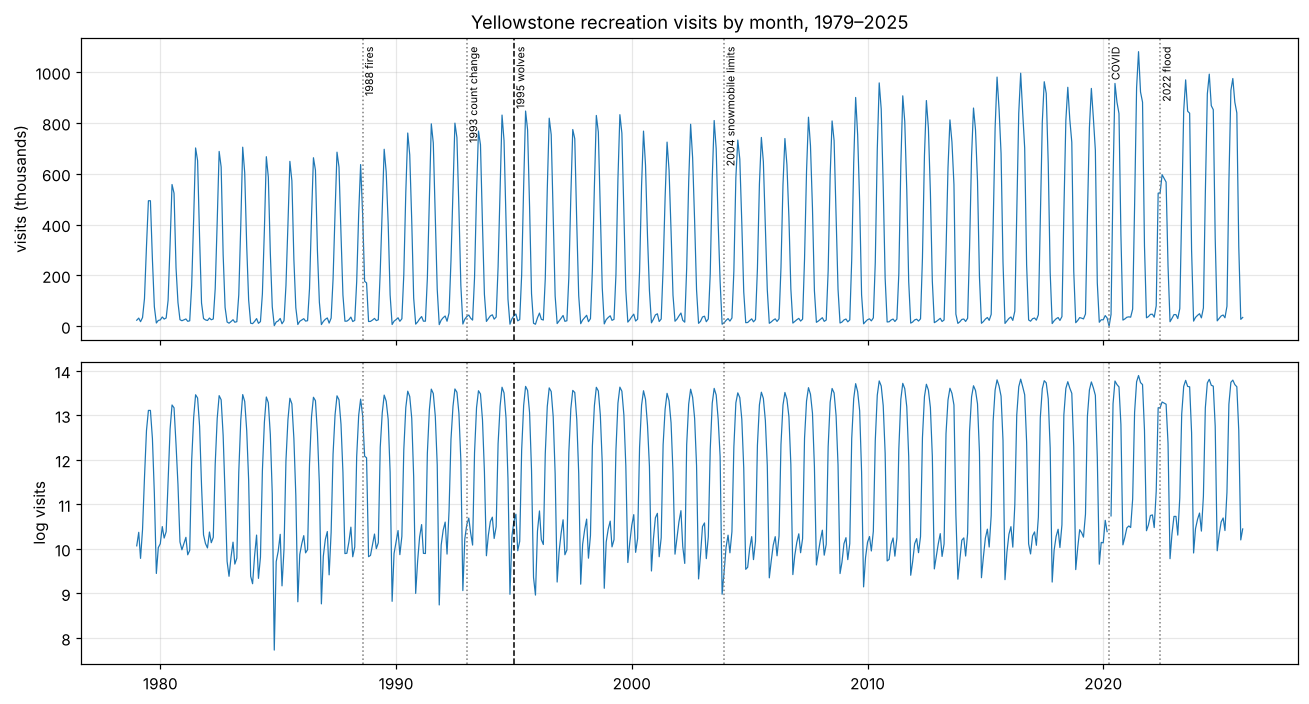

In [2]:
MARKS = {"1988 fires": "1988-08", "1993 count change": "1993-01", "1995 wolves": "1995-01",
         "2004 snowmobile limits": "2003-12", "COVID": "2020-04", "2022 flood": "2022-06"}
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].plot(v.index, v.Visits / 1e3, lw=0.8); ax[0].set_ylabel("visits (thousands)")
ax[1].plot(v.index, y, lw=0.8); ax[1].set_ylabel("log visits")
for a in ax:
    for lab, d in MARKS.items():
        a.axvline(pd.Timestamp(d), color="k" if "wolves" in lab else "gray",
                  ls="--" if "wolves" in lab else ":", lw=1)
for lab, d in MARKS.items():
    ax[0].text(pd.Timestamp(d), ax[0].get_ylim()[1] * 0.97, " " + lab, fontsize=7, va="top", rotation=90)
ax[0].set_title("Yellowstone recreation visits by month, 1979–2025")
fig.tight_layout(); fig.savefig(FIG / "q0_series.png", dpi=150); plt.show()

## Q0.2 STL decomposition (period 12, robust)
Apr 2020 (park closed, 0 visits) has no log; STL needs a complete series, so for the
decomposition only we fill it with the Mar/May average. The robust fit down-weights it anyway.

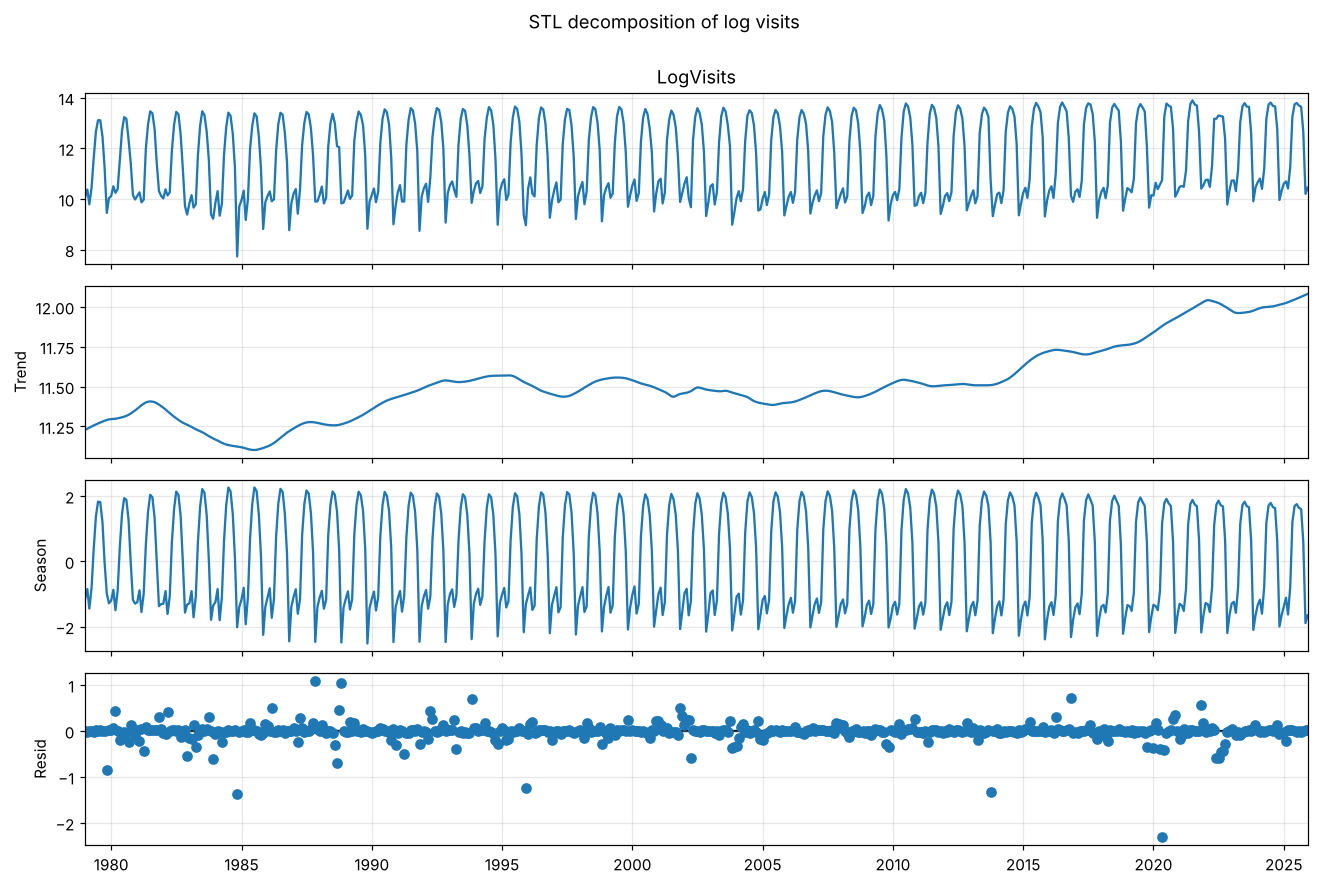

Average seasonal effect (log points), Jan..Dec:
 Date
1    -1.21
2    -1.02
3    -1.58
4    -1.12
5     0.87
6     1.75
7     2.08
8     1.96
9     1.53
10    0.39
11   -2.11
12   -1.54

Seasonal amplitude: Jul/Nov ratio ≈ 66x
Trend: 81,988 -> 163,025 (geometric-mean visits/month)


In [3]:
y_stl = y.copy(); y_stl["2020-04-01"] = (y["2020-03-01"] + y["2020-05-01"]) / 2
stl = STL(y_stl, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(12, 8)
fig.suptitle("STL decomposition of log visits", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "q0_stl.png", dpi=150); plt.show()

seas = stl.seasonal.groupby(stl.seasonal.index.month).mean()
print("Average seasonal effect (log points), Jan..Dec:\n", seas.round(2).to_string())
print(f"\nSeasonal amplitude: Jul/Nov ratio ≈ {np.exp(seas[7] - seas[11]):.0f}x")
print(f"Trend: {np.exp(stl.trend['1980-01-01':'1980-12-01'].mean()):,.0f} -> "
      f"{np.exp(stl.trend['2024-01-01':'2024-12-01'].mean()):,.0f} (geometric-mean visits/month)")

### How stable is the seasonal shape?
Plotting the STL seasonal component by decade shows whether the season has spread
(relevant to Q2).

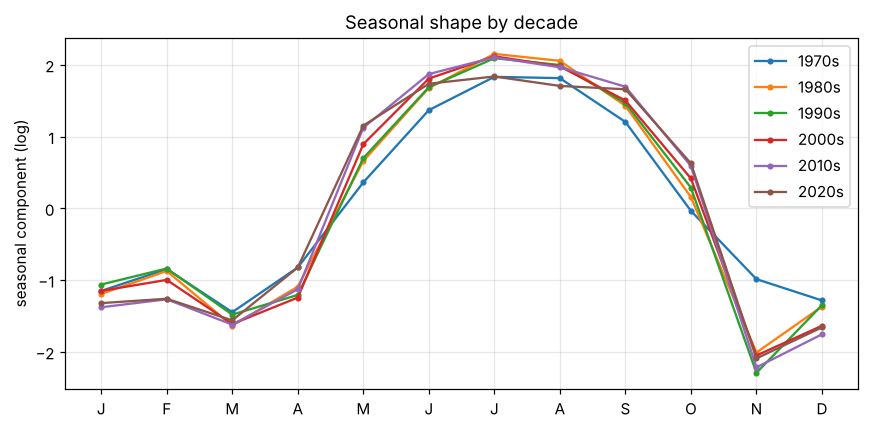

In [4]:
sea = stl.seasonal.to_frame("s"); sea["m"] = sea.index.month; sea["dec"] = (sea.index.year // 10) * 10
fig, ax = plt.subplots(figsize=(8, 4))
for dec, g in sea.groupby("dec"):
    ax.plot(range(1, 13), g.groupby("m").s.mean(), marker="o", ms=3, label=f"{dec}s")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("seasonal component (log)"); ax.legend(); ax.set_title("Seasonal shape by decade")
fig.tight_layout(); fig.savefig(FIG / "q0_seasonal_by_decade.png", dpi=150); plt.show()

## Q0.3 Stationarity: ADF and KPSS
ADF: H0 = unit root. KPSS: H0 = stationary. Agreement means both say the same thing.
(statsmodels caps KPSS p-values at 0.10 and floors them at 0.01.)

In [5]:
def stationarity(s, name):
    s = s.dropna()
    adf = adfuller(s, autolag="AIC")
    kp = kpss(s, regression="c", nlags="auto")
    return {"series": name, "ADF stat": adf[0], "ADF p": adf[1], "KPSS stat": kp[0], "KPSS p": kp[1]}

st = pd.DataFrame([stationarity(y_stl, "log V"),
                   stationarity(y_stl.diff(12), "Δ12 log V"),
                   stationarity(y_stl.diff(12).diff(), "Δ1Δ12 log V")]).round(3)
st.to_csv(TAB / "q0_stationarity.csv", index=False); st

,series,ADF stat,ADF p,KPSS stat,KPSS p
0,log V,-1.319,0.62,0.396,0.079
1,Δ12 log V,-7.939,0.00,0.056,0.100
2,Δ1Δ12 log V,-9.847,0.00,0.016,0.100


**Reading:** the level fails ADF (unit root not rejected). After the seasonal difference
Δ12, ADF rejects strongly and KPSS does not reject, so Δ12 alone is already close to
stationary. Adding Δ1 is the conventional airline-model choice and still passes both tests.
We keep d = 1, D = 1 (as in the brief) and check that the MA(1) term does not hit −1
(which would signal over-differencing).

## Q0.4 ACF / PACF of Δ1Δ12 log visits (to lag 36)

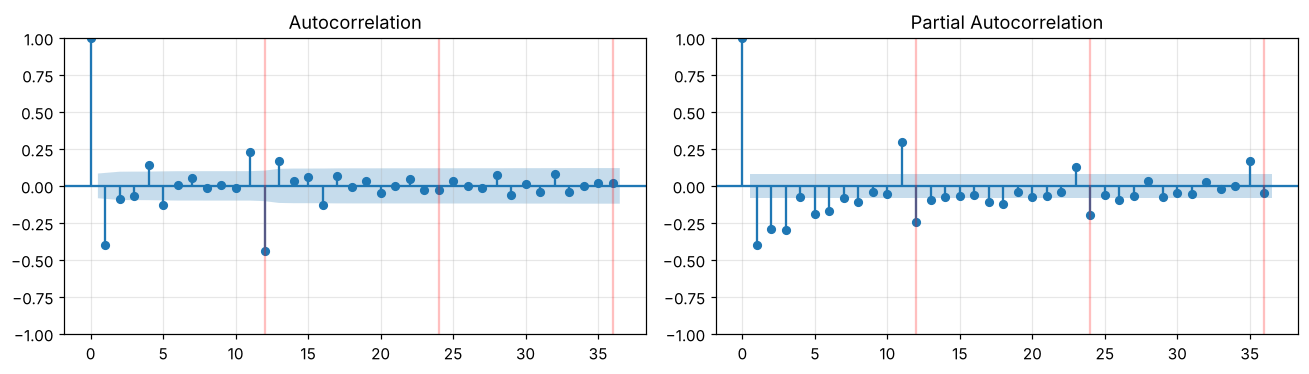

In [6]:
dd = y_stl.diff(12).diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(dd, lags=36, ax=ax[0]); plot_pacf(dd, lags=36, ax=ax[1], method="ywm")
for a in ax:
    for L in (12, 24, 36): a.axvline(L, color="r", alpha=0.25)
fig.tight_layout(); fig.savefig(FIG / "q0_acf_pacf.png", dpi=150); plt.show()

Negative spike at lag 12 in the ACF with a decaying PACF at 12, 24, 36 → seasonal MA(1).
Significant short lags (1–2) → non-seasonal MA terms.

## Q0.5–6 SARIMA order search with shock dummies

Exogenous regressors (so shocks do not distort the noise model; Q3 studies them properly):

| dummy | months |
|---|---|
| `D_fire88` | Jul–Sep 1988 |
| `D_covid20` | Mar–May 2020 (Apr is missing anyway) |
| `D_flood22` | Jun–Oct 2022 |
| `D_shutdown` | Dec 1995, Jan 1996, Oct 2013, Dec 2018, Jan 2019, Oct 2025 |
| `C_count93` | **step** from Jan 1993: NPS switched from manual counts to traffic-counter estimates (IRMA *Count Procedure Changes*) |
| `C_count13` | step from Jan 2013: new persons-per-vehicle multipliers |

In [7]:
EXOG = ["D_fire88", "D_covid20", "D_flood22", "D_shutdown"]
X = v[EXOG].copy()
X["C_count93"] = (v.index >= "1993-01-01").astype(int)
X["C_count13"] = (v.index >= "2013-01-01").astype(int)

rows = []
for p in range(3):
    for q in range(3):
        for P in range(2):
            for Q in range(2):
                m = SARIMAX(y, exog=X, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
                lb = acorr_ljungbox(m.resid.iloc[13:].dropna(), lags=[12, 24])
                rows.append(dict(order=f"({p},1,{q})({P},1,{Q})12", p=p, q=q, P=P, Q=Q,
                                 AIC=m.aic, BIC=m.bic, LB12_p=lb.lb_pvalue.iloc[0], LB24_p=lb.lb_pvalue.iloc[1]))
grid = pd.DataFrame(rows).sort_values("BIC").reset_index(drop=True)
grid.round(3).to_csv(TAB / "q0_sarima_grid.csv", index=False)
grid.head(10).round(3)

,order,p,q,P,Q,AIC,BIC,LB12_p,LB24_p
0,"(0,1,2)(1,1,1)12",0,2,1,1,-70.363,-22.934,0.074,0.072
1,"(2,1,1)(1,1,1)12",2,1,1,1,-72.000,-20.259,0.130,0.067
2,"(0,1,2)(0,1,1)12",0,2,0,1,-61.923,-18.805,0.003,0.015
3,"(1,1,1)(1,1,1)12",1,1,1,1,-66.115,-18.686,0.064,0.073
4,"(1,1,2)(1,1,1)12",1,2,1,1,-68.932,-17.191,0.092,0.074
5,"(2,1,1)(0,1,1)12",2,1,0,1,-63.653,-16.223,0.006,0.012
6,"(1,1,1)(0,1,1)12",1,1,0,1,-57.351,-14.234,0.003,0.013
7,"(1,1,2)(0,1,1)12",1,2,0,1,-60.471,-13.042,0.004,0.015
8,"(2,1,2)(0,1,1)12",2,2,0,1,-61.671,-9.931,0.006,0.010
9,"(0,1,1)(1,1,1)12",0,1,1,1,-49.985,-6.867,0.044,0.018


In [8]:
airline = grid[grid.order == "(0,1,1)(0,1,1)12"].round(3)
print("Airline model for reference:\n", airline.to_string(index=False))

Airline model for reference:
            order  p  q  P  Q     AIC    BIC  LB12_p  LB24_p
(0,1,1)(0,1,1)12  0  1  0  1 -40.293 -1.488   0.001   0.001


**Choice:** lowest BIC among models whose residuals pass Ljung–Box at lag 24 (p > 0.05).
The airline model has clearly worse BIC and fails Ljung–Box, so we move to the nearby order.

In [9]:
ok = grid[grid.LB24_p > 0.05]
best = ok.iloc[0]
ORDER, SORDER = (int(best.p), 1, int(best.q)), (int(best.P), 1, int(best.Q), 12)
print("Chosen:", best.order, f"BIC={best.BIC:.1f}  LB24 p={best.LB24_p:.3f}")
q0 = SARIMAX(y, exog=X, order=ORDER, seasonal_order=SORDER).fit(disp=False)

Chosen: (0,1,2)(1,1,1)12 BIC=-22.9  LB24 p=0.072


In [10]:
coef = pd.DataFrame({"coef": q0.params, "se": q0.bse, "p": q0.pvalues})
coef["% effect"] = np.where(coef.index.isin(X.columns), 100 * (np.exp(coef.coef) - 1), np.nan)
coef.round(3).to_csv(TAB / "q0_sarima_coefficients.csv"); coef.round(3)

,coef,se,p,% effect
D_fire88,-0.432,0.116,0.000,-35.063
D_covid20,-1.063,0.034,0.000,-65.444
D_flood22,-0.437,0.124,0.000,-35.387
D_shutdown,-0.454,0.039,0.000,-36.493
C_count93,0.019,0.087,0.827,1.924
C_count13,-0.104,0.116,0.372,-9.835
ma.L1,-0.715,0.028,0.000,NaN
ma.L2,-0.220,0.031,0.000,NaN
ar.S.L12,0.186,0.042,0.000,NaN
ma.S.L12,-0.833,0.033,0.000,NaN


### Residual diagnostics

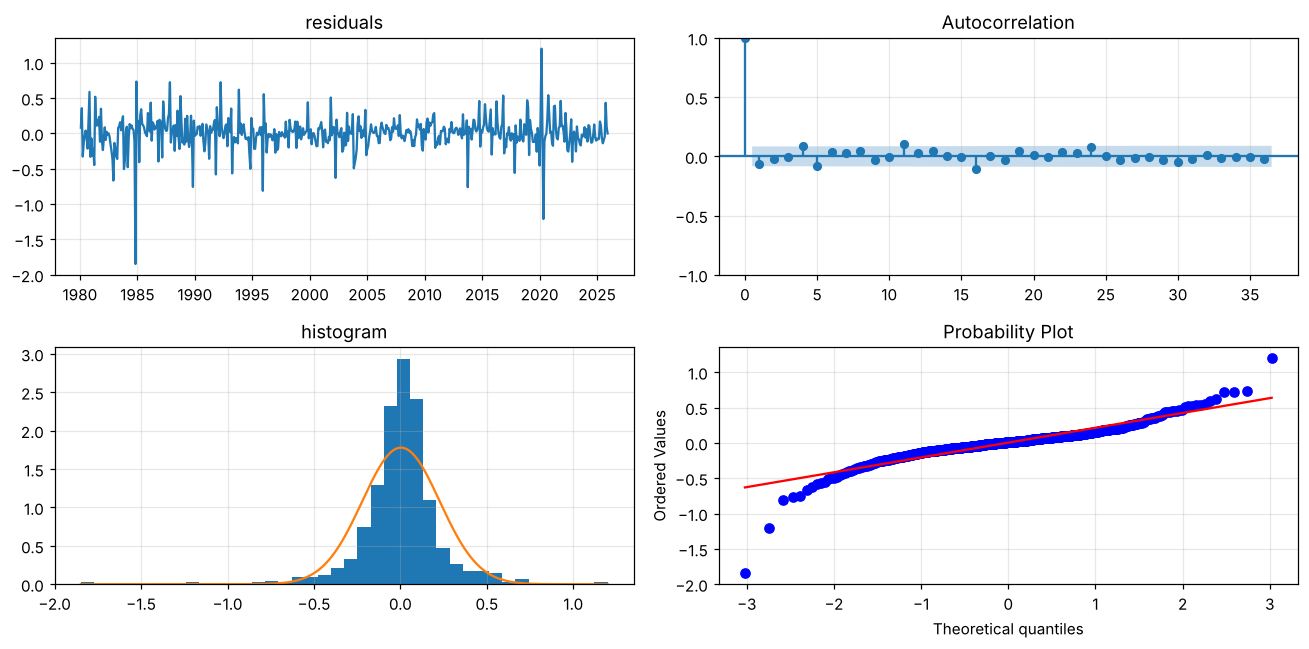

Ljung–Box:
     lb_stat  lb_pvalue
12   19.668      0.074
24   34.774      0.072
36   38.274      0.367
Jarque–Bera p = 0  (heavy tails from remaining odd months)
Largest |residuals|:
 Date
1984-11-01    1.848
2020-05-01    1.212
2020-03-01    1.198
1995-12-01    0.812
2013-10-01    0.761
1989-11-01    0.757
1984-12-01    0.733
1987-11-01    0.724
dtype: float64


In [11]:
r = q0.resid.iloc[13:].dropna()
fig, ax = plt.subplots(2, 2, figsize=(12, 6))
ax[0, 0].plot(r); ax[0, 0].set_title("residuals")
plot_acf(r, lags=36, ax=ax[0, 1])
ax[1, 0].hist(r, bins=40, density=True); xs = np.linspace(r.min(), r.max(), 200)
ax[1, 0].plot(xs, stats.norm.pdf(xs, r.mean(), r.std())); ax[1, 0].set_title("histogram")
stats.probplot(r, plot=ax[1, 1])
fig.tight_layout(); fig.savefig(FIG / "q0_residuals.png", dpi=150); plt.show()
print("Ljung–Box:\n", acorr_ljungbox(r, lags=[12, 24, 36]).round(3))
print(f"Jarque–Bera p = {stats.jarque_bera(r).pvalue:.3g}  (heavy tails from remaining odd months)")
print("Largest |residuals|:\n", r.abs().sort_values(ascending=False).head(8).round(3))

## Q0.7 Stationarity and invertibility of the fitted model
A seasonal ARIMA is only well behaved if, after differencing, its AR part is **stationary** and
its MA part is **invertible**: every root of the AR and MA polynomials must lie *outside* the unit
circle (|root| > 1). An MA root very close to 1 is the textbook sign of **over-differencing** —
the MA term is trying to cancel a difference that was not needed (Box–Jenkins Ch. 4; e.g. Δy of
white noise is an MA(1) with θ = −1).

                     count    min
part                             
AR (incl. seasonal)     12  1.151
MA (incl. seasonal)     14  1.015

Non-seasonal MA polynomial 1 -0.715B -0.220B²: value at B = 1 is 0.064 (0 would mean an exact unit root)
Seasonal MA: 1 -0.833B¹² ; seasonal AR: 1 -0.186B¹²


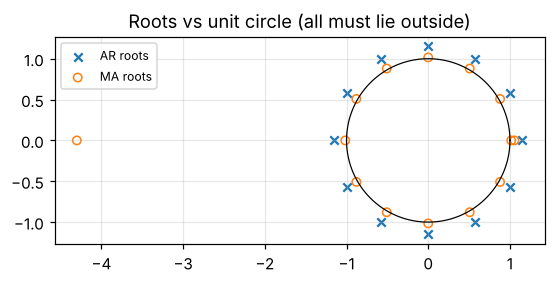

In [12]:
def root_table(res, name):
    out = []
    for kind, roots in (("AR (incl. seasonal)", res.arroots), ("MA (incl. seasonal)", res.maroots)):
        for z in roots:
            out.append(dict(model=name, part=kind, root=complex(z), modulus=abs(z)))
    return pd.DataFrame(out)

roots = root_table(q0, f"SARIMA{ORDER}{SORDER[:3]}")
roots["root"] = roots.root.map(lambda z: f"{z.real:+.3f}{z.imag:+.3f}i")
print(roots.groupby("part").modulus.agg(["count", "min"]).round(3))
ma_nonseas = np.r_[1, q0.params[["ma.L1", "ma.L2"]].values]
print(f"\nNon-seasonal MA polynomial 1 {ma_nonseas[1]:+.3f}B {ma_nonseas[2]:+.3f}B²: "
      f"value at B = 1 is {ma_nonseas.sum():.3f} (0 would mean an exact unit root)")
print(f"Seasonal MA: 1 {q0.params['ma.S.L12']:+.3f}B¹² ; seasonal AR: 1 {-q0.params['ar.S.L12']:+.3f}B¹²")

fig, ax = plt.subplots(figsize=(5, 5))
t = np.linspace(0, 2 * np.pi, 400); ax.plot(np.cos(t), np.sin(t), "k", lw=0.8)
for kind, rr, mk_ in (("AR", q0.arroots, "x"), ("MA", q0.maroots, "o")):
    ax.scatter(np.real(rr), np.imag(rr), marker=mk_, s=30, label=f"{kind} roots", facecolors="none" if mk_ == "o" else None,
               edgecolors="C1" if mk_ == "o" else None, color="C0" if mk_ == "x" else None)
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("Roots vs unit circle (all must lie outside)")
fig.tight_layout(); fig.savefig(FIG / "q0_unit_roots.png", dpi=150); plt.show()
roots.round(3).to_csv(TAB / "q0_roots.csv", index=False)

**Reading:** all roots are outside the unit circle, so the model is stationary and invertible.
But the smallest non-seasonal MA root is only just outside (≈ 1.02), and the MA polynomial almost
vanishes at B = 1. The MA(2) is nearly cancelling the first difference Δ1 — evidence that d = 1
may be one difference too many, consistent with the ADF/KPSS result that Δ12 alone was already
stationary. Section Q0.9 tests the alternative.

## Q0.8 Conditional heteroskedasticity: ARCH-LM test
Ljung–Box tests whether residuals are *correlated*. The ARCH-LM test (Engle 1982) asks a
different question: is the **variance** of the residuals predictable from past squared
residuals (volatility clustering)? If yes, constant-width forecast intervals are too narrow in
turbulent periods and too wide in calm ones.

In [13]:
from statsmodels.stats.diagnostic import het_arch
arch_rows = []
for lab, rr in [("all months", r),
                ("excluding |resid| > 3 SD", r[r.abs() <= 3 * r.std()]),
                ("1979–2019 only", r[:"2019-12-01"])]:
    for L in (12, 24):
        lm, lmp, _, _ = het_arch(rr, nlags=L)
        arch_rows.append(dict(sample=lab, lags=L, LM=lm, p=lmp, n=len(rr)))
lb2 = acorr_ljungbox(r ** 2, lags=[12, 24]).lb_pvalue
arch_tab = pd.DataFrame(arch_rows)
arch_tab.round(4).to_csv(TAB / "q0_arch_lm.csv", index=False)
print("McLeod–Li (Ljung–Box on squared residuals) p:", lb2.round(4).tolist())
arch_tab.round(4)

McLeod–Li (Ljung–Box on squared residuals) p: [0.0018, 0.0143]


,sample,lags,LM,p,n
0,all months,12,31.2749,0.0018,550
1,all months,24,36.7572,0.0463,550
2,excluding |resid| > 3 SD,12,56.1060,0.0000,541
3,excluding |resid| > 3 SD,24,74.1119,0.0000,541
4,1979–2019 only,12,15.2346,0.2289,479
5,1979–2019 only,24,23.5381,0.4882,479


**Reading:** a significant ARCH-LM result means forecast uncertainty is not constant. Here it is
significant over the full sample but not for 1979–2019, so the changing variance comes from the
2020–22 run of extreme months (COVID closure, record rebound, flood), not from persistent
volatility of the kind GARCH models describe. Constant-variance SARIMA intervals are adequate for
normal years; the Q4 rolling forecasts check this in practice.

## Q0.9 Over-differencing check: d = 0 with drift
ADF/KPSS showed Δ12 log visits is already stationary, and Q0.7 found a near-unit MA root. So we
also fit SARIMA(p, **0**, q)(P, 1, Q)₁₂ **with a constant**. After one seasonal difference a
constant is a fixed average yearly growth (drift), instead of a growth rate that is re-estimated
from the most recent years as with d = 1.

BIC cannot compare models with different d (they describe different transformed data), so the
order is chosen by BIC *within* the d = 0 family (Ljung–Box 24 p > 0.05), and the two finalists
are then compared by out-of-sample forecasting in Q4.

In [14]:
rows0 = []
for p_ in range(1, 4):
    for q_ in range(3):
        for P_, Q_ in ((0, 1), (1, 1)):
            m0 = SARIMAX(y, exog=X, order=(p_, 0, q_), seasonal_order=(P_, 1, Q_, 12), trend="c").fit(disp=False, maxiter=200)
            lb = acorr_ljungbox(m0.resid.iloc[13:].dropna(), lags=[12, 24]).lb_pvalue
            rows0.append(dict(order=f"({p_},0,{q_})({P_},1,{Q_})12 + drift", p=p_, q=q_, P=P_, Q=Q_,
                              BIC=m0.bic, LB12_p=lb.iloc[0], LB24_p=lb.iloc[1], min_AR_root=np.abs(m0.arroots).min()))
grid0 = pd.DataFrame(rows0).sort_values("BIC").reset_index(drop=True)
grid0.round(3).to_csv(TAB / "q0_sarima_d0_grid.csv", index=False)
best0 = grid0[grid0.LB24_p > 0.05].iloc[0]
ORDER0, SORDER0 = (int(best0.p), 0, int(best0.q)), (int(best0.P), 1, int(best0.Q), 12)
q0d0 = SARIMAX(y, exog=X, order=ORDER0, seasonal_order=SORDER0, trend="c").fit(disp=False)
print("d = 0 choice:", best0.order, f"BIC={best0.BIC:.1f} LB24 p={best0.LB24_p:.3f} min AR root={best0.min_AR_root:.3f}")
# mean of Δ12 log V = c / (φ(1)·Φ(1)) : the model's fixed long-run yearly growth (log points)
mu12 = q0d0.params["intercept"] / (q0d0.polynomial_ar.sum() * q0d0.polynomial_seasonal_ar.sum())
print(f"Drift: long-run growth {100 * (np.exp(mu12) - 1):+.2f}% per year (fixed, not re-estimated from recent years)")
grid0.head(8).round(3)

d = 0 choice: (1,0,2)(1,1,1)12 + drift BIC=-17.1 LB24 p=0.064 min AR root=1.041
Drift: long-run growth +1.65% per year (fixed, not re-estimated from recent years)


,order,p,q,P,Q,BIC,LB12_p,LB24_p,min_AR_root
0,"(1,0,2)(1,1,1)12 + drift",1,2,1,1,-17.134,0.079,0.064,1.041
1,"(3,0,1)(1,1,1)12 + drift",3,1,1,1,-16.796,0.107,0.043,1.034
2,"(1,0,2)(0,1,1)12 + drift",1,2,0,1,-14.106,0.006,0.022,1.049
3,"(3,0,1)(0,1,1)12 + drift",3,1,0,1,-13.875,0.008,0.016,1.044
4,"(1,0,0)(1,1,1)12 + drift",1,0,1,1,-11.041,0.000,0.000,1.144
5,"(2,0,2)(1,1,1)12 + drift",2,2,1,1,-9.852,0.163,0.098,1.052
6,"(2,0,2)(0,1,1)12 + drift",2,2,0,1,-9.342,0.005,0.013,1.042
7,"(3,0,2)(1,1,1)12 + drift",3,2,1,1,-7.698,0.108,0.041,1.046


In [15]:
cmp_ = pd.DataFrame({"d = 1 (chosen in Q0.5)": q0.params[X.columns], "d = 0 + drift": q0d0.params[X.columns]})
cmp_ = 100 * (np.exp(cmp_) - 1)
print("Shock / count-change effects (%) under both models:"); cmp_.round(1)

Shock / count-change effects (%) under both models:


,d = 1 (chosen in Q0.5),d = 0 + drift
D_fire88,-35.1,-34.9
D_covid20,-65.4,-65.2
D_flood22,-35.4,-34.0
D_shutdown,-36.5,-37.4
C_count93,1.9,-0.4
C_count13,-9.8,4.5


## Q0.10 Forecast function and ψ-weights — how each model extrapolates growth
Any ARIMA can be written as an infinite MA, z_t = Σ ψ_j a_{t−j} (Box–Jenkins Ch. 4–5): ψ_j is how
much a shock j months ago still moves z today, and the j-step forecast error variance is
σ² Σ_{i<j} ψ_i². Here we look at **z = Δ12 log V, the year-on-year growth rate**, because the
question is what the models assume about growth.

* d = 1: (1 − ΦB¹²)(1 − B) z_t = (1 + θ₁B + θ₂B²)(1 + ΘB¹²) a_t. Because of the (1 − B), the ψ-weights
  of z converge to a **non-zero constant**, ψ_∞ = θ(1)Θ(1)/Φ(1): every shock permanently changes
  the growth rate a little. Growth is a random walk; the forecast slope is "recent growth".
* d = 0 + drift: (1 − φ₁B)(1 − ΦB¹²) z_t = c + θ(B)Θ(B¹²) a_t. The ψ-weights of z decay to **0**:
  shocks fade and growth returns to the fixed drift.

The **eventual forecast function** follows: a fixed seasonal pattern plus a straight line in log
visits whose slope is the current growth estimate (d = 1) or the long-run drift (d = 0).

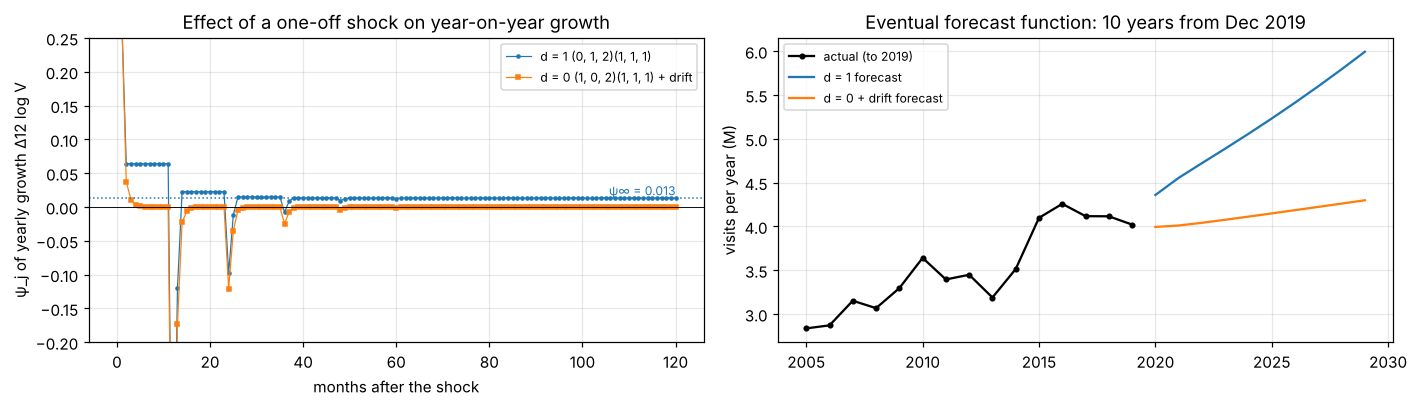

Implied yearly growth of the eventual forecast: d = 1 +3.5%/yr, d = 0 + drift +0.8%/yr; actual 1995–2019 average +2.8%/yr
ψ-weights of yearly growth at lags 24, 60, 120: d = 1 [-0.098  0.012  0.013] (→ 0.013), d = 0 [-0.121 -0.001 -0.   ] (→ 0)
The d = 1 limit is small because θ(1) = 1 + θ1 + θ2 is close to 0 (the near-unit MA root from Q0.7):
the fitted MA almost cancels the first difference, but not completely, so recent growth still carries forward.


In [16]:
def psi_weights(res, d, D, s=12, n=72):
    # statsmodels stores the non-seasonal and seasonal lag polynomials separately; multiply them
    ar = np.convolve(res.polynomial_ar, res.polynomial_seasonal_ar)   # φ(B)Φ(B^s): [1, −φ1, ...]
    ma = np.convolve(res.polynomial_ma, res.polynomial_seasonal_ma)   # θ(B)Θ(B^s): [1, θ1, ...]
    ar = np.array(ar, float); ma = np.array(ma, float)
    for _ in range(d):
        ar = np.convolve(ar, [1, -1])
    for _ in range(D):
        ar = np.convolve(ar, np.r_[1, np.zeros(s - 1), -1])
    return ArmaProcess(ar, ma).arma2ma(n)

NPSI = 121
psi1 = psi_weights(q0, d=1, D=0, n=NPSI)      # ψ-weights of Δ12 log V under d = 1
psi0 = psi_weights(q0d0, d=0, D=0, n=NPSI)    # ψ-weights of Δ12 log V under d = 0
lim1 = (np.convolve(q0.polynomial_ma, q0.polynomial_seasonal_ma).sum()
        / np.convolve(q0.polynomial_ar, q0.polynomial_seasonal_ar).sum())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(np.arange(NPSI), psi1, "o-", ms=2, lw=0.8, label=f"d = 1 {ORDER}{SORDER[:3]}")
ax[0].plot(np.arange(NPSI), psi0, "s-", ms=2, lw=0.8, label=f"d = 0 {ORDER0}{SORDER0[:3]} + drift")
ax[0].axhline(lim1, color="C0", ls=":", lw=1); ax[0].text(NPSI - 1, lim1, f" ψ∞ = {lim1:.3f}", color="C0", fontsize=8, va="bottom", ha="right")
ax[0].axhline(0, color="k", lw=0.6); ax[0].set_ylim(-0.2, 0.25)
ax[0].set_xlabel("months after the shock"); ax[0].set_ylabel("ψ_j of yearly growth Δ12 log V")
ax[0].set_title("Effect of a one-off shock on year-on-year growth"); ax[0].legend(fontsize=8)

# Eventual forecast function: forecast 10 years ahead from Dec 2019 with both models
cut = pd.Timestamp("2019-12-01"); hz = 120
idx_f = pd.date_range(cut + pd.DateOffset(months=1), periods=hz, freq="MS")
Xf = pd.DataFrame(0, index=idx_f, columns=X.columns); Xf[["C_count93", "C_count13"]] = 1
f1 = SARIMAX(y[:cut], exog=X[:cut], order=ORDER, seasonal_order=SORDER).fit(disp=False).get_forecast(hz, exog=Xf).predicted_mean
f0 = SARIMAX(y[:cut], exog=X[:cut], order=ORDER0, seasonal_order=SORDER0, trend="c").fit(disp=False).get_forecast(hz, exog=Xf).predicted_mean
ann1, ann0 = np.exp(f1).groupby(f1.index.year).sum(), np.exp(f0).groupby(f0.index.year).sum()
hist = v.Visits[:cut].groupby(v.Visits[:cut].index.year).sum().loc[2005:]
ax[1].plot(hist.index, hist / 1e6, "k-o", ms=3, label="actual (to 2019)")
ax[1].plot(ann1.index, ann1 / 1e6, "C0-", label="d = 1 forecast")
ax[1].plot(ann0.index, ann0 / 1e6, "C1-", label="d = 0 + drift forecast")
ax[1].set_ylabel("visits per year (M)"); ax[1].set_title("Eventual forecast function: 10 years from Dec 2019")
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "q0_psi_weights_forecast_function.png", dpi=150); plt.show()

g1 = 100 * (np.exp(np.polyfit(np.arange(10), np.log(ann1.values[:10]), 1)[0]) - 1)
g0 = 100 * (np.exp(np.polyfit(np.arange(10), np.log(ann0.values[:10]), 1)[0]) - 1)
gh = 100 * (np.exp(np.polyfit(np.arange(len(hist.loc[1995:])), np.log(hist.loc[1995:].values), 1)[0]) - 1)
print(f"Implied yearly growth of the eventual forecast: d = 1 {g1:+.1f}%/yr, d = 0 + drift {g0:+.1f}%/yr; "
      f"actual 1995–2019 average {gh:+.1f}%/yr")
print(f"ψ-weights of yearly growth at lags 24, 60, 120: d = 1 {np.round(psi1[[24, 60, 120]], 3)} (→ {lim1:.3f}), "
      f"d = 0 {np.round(psi0[[24, 60, 120]], 3)} (→ 0)")
print("The d = 1 limit is small because θ(1) = 1 + θ1 + θ2 is close to 0 (the near-unit MA root from Q0.7):")
print("the fitted MA almost cancels the first difference, but not completely, so recent growth still carries forward.")

In [17]:
spec = {"order": ORDER, "seasonal_order": SORDER, "exog": list(X.columns),
        "note": "log visits; chosen by BIC subject to Ljung-Box(24) p>0.05 in notebook 13"}
(TAB / "q0_sarima_spec.json").write_text(json.dumps(spec, indent=2))
spec0 = {"order": ORDER0, "seasonal_order": SORDER0, "trend": "c", "exog": list(X.columns),
         "note": "d=0 + drift alternative, chosen by BIC within d=0 family (Q0.9)"}
(TAB / "q0_sarima_d0_spec.json").write_text(json.dumps(spec0, indent=2)); spec, spec0

({'order': (0, 1, 2),
  'seasonal_order': (1, 1, 1, 12),
  'exog': ['D_fire88',
   'D_covid20',
   'D_flood22',
   'D_shutdown',
   'C_count93',
   'C_count13'],
  'note': 'log visits; chosen by BIC subject to Ljung-Box(24) p>0.05 in notebook 13'},
 {'order': (1, 0, 2),
  'seasonal_order': (1, 1, 1, 12),
  'trend': 'c',
  'exog': ['D_fire88',
   'D_covid20',
   'D_flood22',
   'D_shutdown',
   'C_count93',
   'C_count13'],
  'note': 'd=0 + drift alternative, chosen by BIC within d=0 family (Q0.9)'})

---
# Q4 — How well can monthly visits be forecast?

**Design**
* Rolling origin: at each month-end *m* from Dec 2009 onward, refit on data up to *m*,
  forecast 1 and 12 months ahead. Main scoring window: targets in **2010–2019**.
  Targets in **2020–2025** are scored separately (COVID, flood) — no model can foresee those.
* Models
  1. **Seasonal naive**: same month last year.
  2. **SARIMA** from Q0 on log visits with the count-procedure steps and shutdown dummies.
     Shock dummies for future months are set to 0 — the forecaster does not know a shock is coming.
     Forecasts are back-transformed with the log-normal bias correction exp(μ + σ²/2).
  3. **Holt–Winters**: additive trend, multiplicative seasonality, on visits.
  4. **ETS (auto)**: all error/trend/seasonal combinations fitted on data to Dec 2009,
     best by AIC; that specification is then re-estimated at every origin.
  5. **SARIMA d = 0 + drift** from Q0.9 (the over-differencing check), same exogenous setup as 2.
* HW and ETS cannot take the zero in Apr 2020 (multiplicative seasonality) or shock dummies,
  so for those two models the COVID (Mar–May 2020) and flood (Jun–Oct 2022) months in the
  **training data** are replaced by the same month one year earlier. Scoring always uses actuals.
* Metrics: MAE, MAPE, MASE (Hyndman & Koehler 2006: MAE ÷ in-sample MAE of the seasonal
  naive on 1979–2009), and relative MAE vs seasonal naive on the same targets.

In [18]:
H = (1, 12)
visits = v.Visits
shock_months = v.index[(v.D_covid20 == 1) | (v.D_flood22 == 1)]
visits_clean = visits.copy()
for d in shock_months:
    visits_clean[d] = visits[d - pd.DateOffset(years=1)]

# ETS specification chosen once on the initial window
train0 = visits_clean[:"2009-12-01"]
ets_rows = []
for err in ("add", "mul"):
    for trend in (None, "add"):
        for damped in ((False, True) if trend else (False,)):
            for seasonal in ("add", "mul"):
                try:
                    f = ETSModel(train0, error=err, trend=trend, damped_trend=damped,
                                 seasonal=seasonal, seasonal_periods=12).fit(disp=False)
                    ets_rows.append(dict(error=err, trend=trend, damped=damped, seasonal=seasonal, AIC=f.aic))
                except Exception as e:
                    print(err, trend, seasonal, e)
ets_grid = pd.DataFrame(ets_rows).sort_values("AIC").reset_index(drop=True)
ETS_SPEC = ets_grid.iloc[0][["error", "trend", "damped", "seasonal"]].to_dict()
ETS_SPEC["trend"] = None if pd.isna(ETS_SPEC["trend"]) else ETS_SPEC["trend"]
ets_grid.round(1).to_csv(TAB / "q4_ets_selection.csv", index=False)
print("ETS chosen:", ETS_SPEC); ets_grid.round(1)

ETS chosen: {'error': 'mul', 'trend': None, 'damped': False, 'seasonal': 'mul'}


,error,trend,damped,seasonal,AIC
0,mul,NaN,False,mul,8486.2
1,mul,add,True,mul,8493.5
2,mul,add,False,mul,8511.1
3,mul,NaN,False,add,8695.4
4,add,add,False,mul,8984.3
5,add,NaN,False,mul,8987.8
6,add,NaN,False,add,9218.5
7,add,add,False,add,9223.5
8,add,add,True,add,9224.8
9,add,add,True,mul,9694.6


### Rolling forecasts (computed in a separate step)
Refitting four models at 192 origins takes several minutes, so the loop lives in
`scripts/q4_rolling_forecasts.py` (same model definitions as described above). Run it once:

```
python scripts/q4_rolling_forecasts.py
```
It writes `reports/tables/q4_rolling_forecasts.csv`, loaded here.

In [19]:
fcs = pd.read_csv(TAB / "q4_rolling_forecasts.csv", parse_dates=["origin", "target"])
print(len(fcs), "forecasts |", fcs.origin.min().date(), "to", fcs.origin.max().date(), "origins")
fcs.groupby(["model", "h"]).size().unstack()

1865 forecasts | 2009-12-01 to 2025-11-01 origins


h,1,12
model,,
ETS,192,181
Holt–Winters,192,181
SARIMA,192,181
SARIMA d=0 + drift,192,181
Seasonal naive,192,181


In [20]:
snv_scale = (visits[:"2009-12-01"] - visits[:"2009-12-01"].shift(12)).abs().mean()   # MASE denominator

def score(d):
    e = (d.forecast - d.actual).abs()
    nz = d.actual > 0
    return pd.Series({"n": len(d), "MAE": e.mean(),
                      "MAPE %": 100 * (e[nz] / d.actual[nz]).mean(), "MASE": e.mean() / snv_scale})

fcs["period"] = np.where(fcs.target.dt.year <= 2019, "2010–2019", "2020–2025 (shocks)")
sc = fcs.groupby(["period", "h", "model"]).apply(score).reset_index()
base = sc[sc.model == "Seasonal naive"].set_index(["period", "h"]).MAE
sc["rel MAE vs snaive"] = sc.apply(lambda r: r.MAE / base[(r.period, r.h)], axis=1)
sc = sc.sort_values(["period", "h", "MASE"])
sc.round(3).to_csv(TAB / "q4_forecast_scores.csv", index=False)
sc.round(3)

,period,h,model,n,MAE,MAPE %,MASE,rel MAE vs snaive
3,2010–2019,1,SARIMA d=0 + drift,120.0,22982.563,12.703,1.179,0.921
1,2010–2019,1,Holt–Winters,120.0,24846.990,14.711,1.275,0.996
4,2010–2019,1,Seasonal naive,120.0,24949.108,14.007,1.280,1.000
0,2010–2019,1,ETS,120.0,26867.141,13.571,1.379,1.077
2,2010–2019,1,SARIMA,120.0,27537.384,13.809,1.413,1.104
9,2010–2019,12,Seasonal naive,109.0,24087.523,13.888,1.236,1.000
5,2010–2019,12,ETS,109.0,25859.247,13.539,1.327,1.074
8,2010–2019,12,SARIMA d=0 + drift,109.0,26984.824,13.665,1.385,1.120
6,2010–2019,12,Holt–Winters,109.0,28479.263,15.628,1.461,1.182
7,2010–2019,12,SARIMA,109.0,30103.355,14.792,1.545,1.250


### Accuracy by calendar month (2010–2019, h = 1)
Absolute errors are dominated by summer, percentage errors by the tiny shoulder/winter months.

In [21]:
m1 = fcs[(fcs.h == 1) & (fcs.period == "2010–2019")].copy()
m1["APE"] = 100 * (m1.forecast - m1.actual).abs() / m1.actual
by_m = m1.pivot_table(index=m1.target.dt.month, columns="model", values="APE", aggfunc="mean")
by_m.index.name = "month"; by_m.round(1)

model,ETS,Holt–Winters,SARIMA,SARIMA d=0 + drift,Seasonal naive
month,,,,,
1,11.9,12.3,11.2,8.1,4.8
2,13.0,13.4,16.3,13.7,7.8
3,8.0,10.1,7.4,6.8,9.6
4,15.8,16.6,14.3,14.0,21.0
5,12.5,9.4,12.7,14.4,10.9
6,6.6,7.5,6.6,3.9,6.7
7,7.1,6.5,7.1,4.2,4.9
8,6.4,4.5,6.7,4.7,6.8
9,8.3,9.2,9.3,9.8,6.8


### Diebold–Mariano test between the two best models (2010–2019)
Absolute-error loss, HAC variance with h−1 lags, Harvey–Leybourne–Newbold small-sample correction.

In [22]:
def dm_test(e1, e2, h):
    d = np.abs(e1) - np.abs(e2); n = len(d); dbar = d.mean()
    gam = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gam[0] + 2 * sum(gam[1:])) / n
    stat = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stat, 2 * stats.t.sf(abs(stat), df=n - 1)

dm_rows = []
for h in H:
    s = sc[(sc.period == "2010–2019") & (sc.h == h)].sort_values("MAE")
    a, b = s.model.iloc[0], s.model.iloc[1]
    w = fcs[(fcs.period == "2010–2019") & (fcs.h == h)].pivot_table(index="target", columns="model", values="forecast")
    act = visits.reindex(w.index)
    stat, p = dm_test((w[a] - act).values, (w[b] - act).values, h)
    dm_rows.append(dict(h=h, best=a, second=b, DM=stat, p=p))
dm = pd.DataFrame(dm_rows); dm.round(3).to_csv(TAB / "q4_diebold_mariano.csv", index=False); dm.round(3)

,h,best,second,DM,p
0,1,SARIMA d=0 + drift,Holt–Winters,-0.716,0.476
1,12,Seasonal naive,ETS,-0.737,0.463


## Q4b Forecast combination and encompassing
With no clear winner, combining forecasts often beats every single model, because different
models make different mistakes (Bates & Granger 1969; Diebold Ch. 12).

* **Equal-weight combinations** (arithmetic mean of the forecasts) of fixed sets chosen in
  advance — not picked by looking at 2010–19 scores, which would bias the comparison.
* **Bates–Granger weights**: weights ∝ 1 / MSE of each model's past log errors, using only
  forecasts whose targets were already observed at the forecast origin (equal weights until 12
  past errors exist). This is a real-time rule, so it is a fair test.
* **Encompassing test** (Harvey, Leybourne & Newbold 1998): regress e₁ on (e₁ − e₂) with
  e = log actual − log forecast. H0: λ = 0 means model 1 *encompasses* model 2 — model 2's
  forecast adds nothing once model 1's is known. Rejecting H0 means model 2 carries extra
  information, so combining the two should help. HAC errors with h lags.

In [23]:
SINGLE = [m for m in ["Seasonal naive", "ETS", "Holt–Winters", "SARIMA", "SARIMA d=0 + drift"] if m in fcs.model.unique()]
wide = fcs.pivot_table(index=["h", "origin", "target"], columns="model", values="forecast").reset_index()
wide["actual"] = visits.reindex(wide.target).values

COMBOS = {"Combo: ETS + Seasonal naive": ["ETS", "Seasonal naive"],
          "Combo: ETS + HW + Seasonal naive": ["ETS", "Holt–Winters", "Seasonal naive"],
          "Combo: all models": SINGLE}
for name, ms in COMBOS.items():
    wide[name] = wide[ms].mean(axis=1)

# Bates–Granger real-time inverse-MSE weights
# log errors; forecasts and actuals floored at 1 visit (the seasonal naive forecasts 0 for Apr 2021,
# copying the closed Apr 2020, which would otherwise give an infinite error)
loge = {m: np.log(wide.actual.clip(lower=1)) - np.log(wide[m].clip(lower=1)) for m in SINGLE}
bg = np.full(len(wide), np.nan)
for h in H:
    sub = wide[wide.h == h].sort_values("origin")
    for i, row in sub.iterrows():
        past = sub[sub.target <= row.origin]
        if len(past) >= 12:
            mse = np.array([(loge[m][past.index] ** 2).mean() for m in SINGLE])
            w = (1 / mse) / (1 / mse).sum()
        else:
            w = np.ones(len(SINGLE)) / len(SINGLE)
        bg[i] = float(np.dot(w, row[SINGLE].values.astype(float)))
wide["Combo: Bates–Granger weights"] = bg
ALLM = SINGLE + list(COMBOS) + ["Combo: Bates–Granger weights"]

long = wide.melt(id_vars=["h", "origin", "target", "actual"], value_vars=ALLM, var_name="model", value_name="forecast")
long["period"] = np.where(long.target.dt.year <= 2019, "2010–2019", "2020–2025 (shocks)")
scc = long.groupby(["period", "h", "model"]).apply(score).reset_index().sort_values(["period", "h", "MASE"])
scc.round(3).to_csv(TAB / "q4b_combination_scores.csv", index=False)

# best combination vs best single model, Diebold–Mariano
cmp_rows = []
for h in H:
    s10 = scc[(scc.period == "2010–2019") & (scc.h == h)]
    best_single = s10[s10.model.isin(SINGLE)].iloc[0].model
    best_combo = s10[~s10.model.isin(SINGLE)].iloc[0].model
    w = long[(long.period == "2010–2019") & (long.h == h)].pivot_table(index="target", columns="model", values="forecast")
    act = visits.reindex(w.index)
    st_, p_ = dm_test((w[best_combo] - act).values, (w[best_single] - act).values, h)
    cmp_rows.append(dict(h=h, best_combo=best_combo,
                         combo_MASE=s10.set_index("model").loc[best_combo, "MASE"],
                         best_single=best_single, single_MASE=s10.set_index("model").loc[best_single, "MASE"],
                         DM=st_, p=p_))
combo_vs = pd.DataFrame(cmp_rows); combo_vs.round(3).to_csv(TAB / "q4b_combo_vs_single_dm.csv", index=False)
for _, c_ in combo_vs.iterrows():
    print(f"h = {c_.h}: best combination {c_.best_combo} (MASE {c_.combo_MASE:.2f}) vs best single model "
          f"{c_.best_single} ({c_.single_MASE:.2f}); Diebold–Mariano p = {c_.p:.2f}")
scc[scc.period == "2010–2019"].round(3)

h = 1: best combination Combo: ETS + HW + Seasonal naive (MASE 1.14) vs best single model SARIMA d=0 + drift (1.18); Diebold–Mariano p = 0.61
h = 12: best combination Combo: ETS + Seasonal naive (MASE 1.20) vs best single model Seasonal naive (1.24); Diebold–Mariano p = 0.66


,period,h,model,n,MAE,MAPE %,MASE
1,2010–2019,1,Combo: ETS + HW + Seasonal naive,120.0,22189.639,12.744,1.139
3,2010–2019,1,Combo: all models,120.0,22793.118,12.610,1.170
7,2010–2019,1,SARIMA d=0 + drift,120.0,22982.563,12.703,1.179
0,2010–2019,1,Combo: Bates–Granger weights,120.0,23050.444,12.655,1.183
2,2010–2019,1,Combo: ETS + Seasonal naive,120.0,23070.277,12.977,1.184
5,2010–2019,1,Holt–Winters,120.0,24846.990,14.711,1.275
8,2010–2019,1,Seasonal naive,120.0,24949.108,14.007,1.280
4,2010–2019,1,ETS,120.0,26867.141,13.571,1.379
6,2010–2019,1,SARIMA,120.0,27537.384,13.809,1.413
11,2010–2019,12,Combo: ETS + Seasonal naive,109.0,23482.173,13.265,1.205


In [24]:
def encompass(e1, e2, h):
    """HLN encompassing regression e1 = λ(e1 − e2) + u. Returns λ and HAC p-value for H0: λ = 0."""
    d = pd.DataFrame({"e1": e1, "x": e1 - e2}).dropna()
    r_ = sm.OLS(d.e1, d.x).fit(cov_type="HAC", cov_kwds={"maxlags": max(h, 1)})
    return r_.params.iloc[0], r_.pvalues.iloc[0]

enc_rows = []
for h in H:
    w = wide[(wide.h == h) & (wide.target.dt.year <= 2019)]
    for m1 in SINGLE:
        for m2 in SINGLE:
            if m1 == m2:
                continue
            lam, pv = encompass(loge[m1][w.index], loge[m2][w.index], h)
            enc_rows.append(dict(h=h, model_1=m1, model_2=m2, lam=lam, p=pv))
enc = pd.DataFrame(enc_rows)
enc.round(4).to_csv(TAB / "q4b_encompassing.csv", index=False)
for h in H:
    print(f"\nh = {h}: p-value for H0 'row model encompasses column model' (small p = column adds information)")
    print(enc[enc.h == h].pivot(index="model_1", columns="model_2", values="p").round(3).to_string())


h = 1: p-value for H0 'row model encompasses column model' (small p = column adds information)
model_2               ETS  Holt–Winters  SARIMA  SARIMA d=0 + drift  Seasonal naive
model_1                                                                            
ETS                   NaN         0.251   0.058               0.033           0.954
Holt–Winters        0.000           NaN   0.000               0.000           0.046
SARIMA              0.020         0.141     NaN               0.029           0.980
SARIMA d=0 + drift  0.052         0.111   0.258                 NaN           0.574
Seasonal naive      0.000         0.000   0.000               0.000             NaN

h = 12: p-value for H0 'row model encompasses column model' (small p = column adds information)
model_2               ETS  Holt–Winters  SARIMA  SARIMA d=0 + drift  Seasonal naive
model_1                                                                            
ETS                   NaN         0.412   0.344    

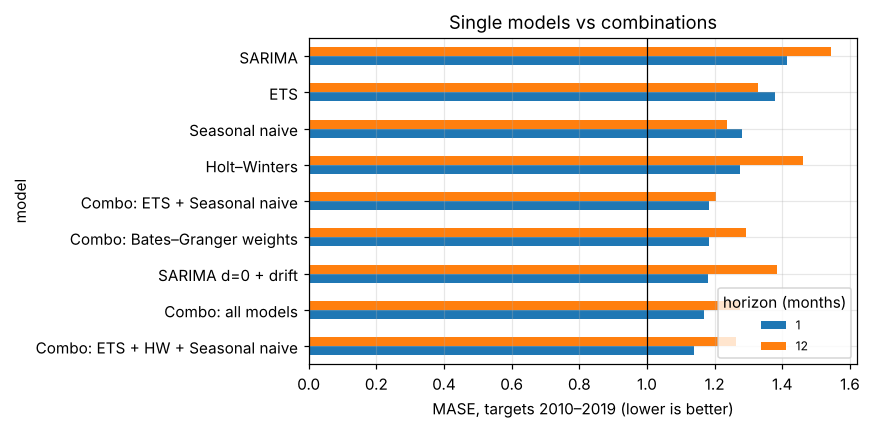

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
pv = scc[scc.period == "2010–2019"].pivot(index="model", columns="h", values="MASE").sort_values(1)
pv.plot.barh(ax=ax, color=["C0", "C1"]); ax.axvline(1, color="k", lw=0.8)
ax.set_xlabel("MASE, targets 2010–2019 (lower is better)"); ax.set_title("Single models vs combinations")
ax.legend(title="horizon (months)", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "q4b_combinations.png", dpi=150); plt.show()

### Figure: rolling 1- and 12-month-ahead forecasts vs actual

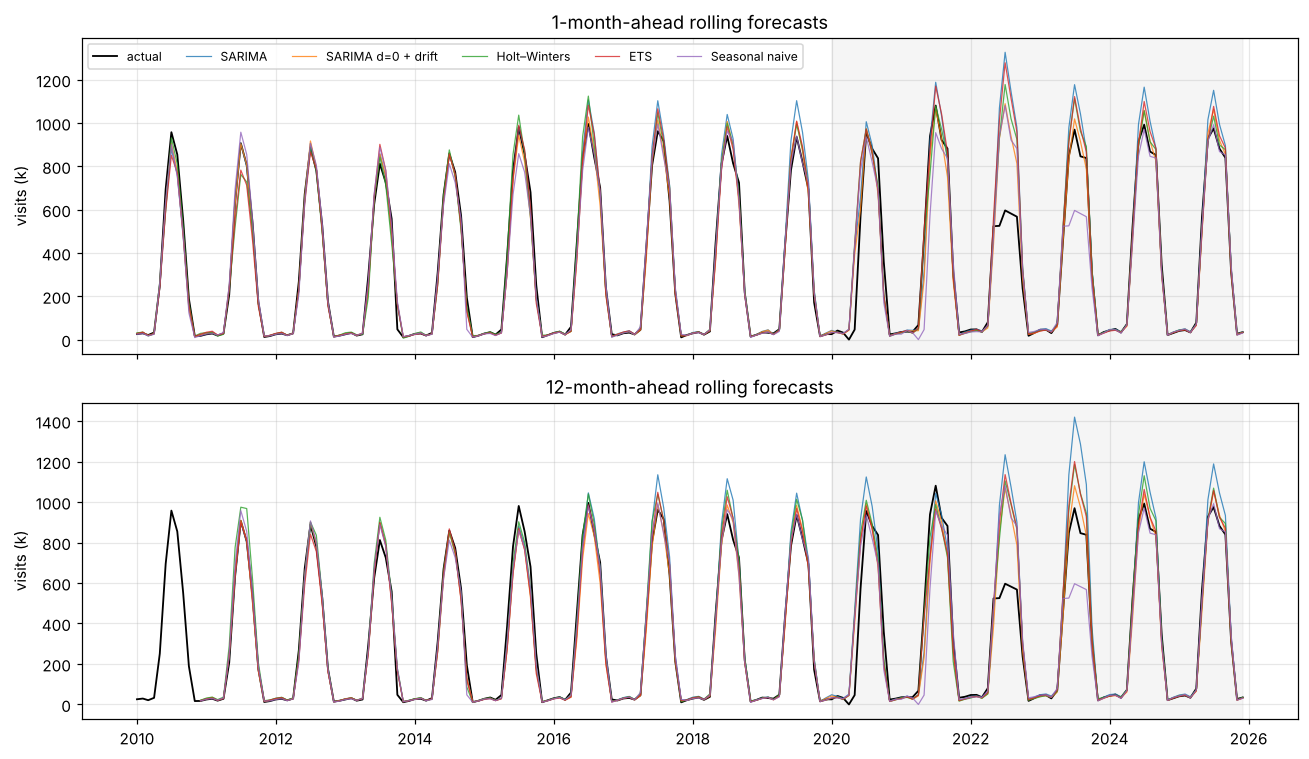

In [26]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for a, h in zip(ax, H):
    sub = fcs[fcs.h == h]
    a.plot(visits["2010":] / 1e3, color="k", lw=1.2, label="actual")
    for name in [m for m in ["SARIMA", "SARIMA d=0 + drift", "Holt–Winters", "ETS", "Seasonal naive"] if m in set(sub.model)]:
        s = sub[sub.model == name].set_index("target").forecast
        a.plot(s / 1e3, lw=0.8, alpha=0.8, label=name)
    a.set_title(f"{h}-month-ahead rolling forecasts"); a.set_ylabel("visits (k)")
    a.axvspan(pd.Timestamp("2020-01-01"), visits.index[-1], color="gray", alpha=0.08)
ax[0].legend(ncol=6, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "q4_rolling_forecasts.png", dpi=150); plt.show()

**Reading the plot:** SARIMA overshoots the summer peaks in most years from 2015 to 2019. With
both d = 1 and D = 1 it extrapolates the most recent year-on-year growth, so after a strong
summer it predicts an even stronger one. ETS (no trend) and the seasonal naive do not, which is
why they rank higher. In 2020–2025 (grey) every model misses COVID and the 2022 flood.

## Final 24-month forecast (Jan 2026 – Dec 2027)
Ranking = average MASE over h = 1 and 12 in 2010–2019. If the seasonal naive comes out on top,
it gives no model-based intervals, so the final forecast uses the best-ranked **statistical**
model (SARIMA, Holt–Winters or ETS). That is justified only if the Diebold–Mariano test above
finds no significant difference from the winner — check before reporting. The first ten months
are compared with the preliminary 2026 IRMA numbers as an informal out-of-sample check.

In [27]:
win = (sc[sc.period == "2010–2019"].groupby("model").MASE.mean().sort_values())
WIN = win.index[0]
FINAL = [m for m in win.index if m != "Seasonal naive"][0]
print("Average MASE 2010–2019:\n", win.round(3).to_string(), f"\nBest overall: {WIN} | used for final forecast: {FINAL}")

end = visits.index[-1]; idx = pd.date_range(end + pd.DateOffset(months=1), periods=24, freq="MS")
if FINAL == "SARIMA":
    fit = SARIMAX(y, exog=X, order=ORDER, seasonal_order=SORDER).fit(disp=False)
    Xf = pd.DataFrame(0, index=idx, columns=X.columns); Xf[["C_count93", "C_count13"]] = 1
    pr = fit.get_forecast(24, exog=Xf)
    mu, sd = pr.predicted_mean, np.sqrt(pr.var_pred_mean)
    out = pd.DataFrame({"forecast": np.exp(mu + sd**2 / 2)}, index=idx)
    for lev, z in ((80, 1.2816), (95, 1.96)):
        out[f"lo{lev}"], out[f"hi{lev}"] = np.exp(mu - z * sd), np.exp(mu + z * sd)
elif FINAL == "SARIMA d=0 + drift":
    fit = SARIMAX(y, exog=X, order=ORDER0, seasonal_order=SORDER0, trend="c").fit(disp=False)
    Xf = pd.DataFrame(0, index=idx, columns=X.columns); Xf[["C_count93", "C_count13"]] = 1
    pr = fit.get_forecast(24, exog=Xf)
    mu, sd = pr.predicted_mean, np.sqrt(pr.var_pred_mean)
    out = pd.DataFrame({"forecast": np.exp(mu + sd**2 / 2)}, index=idx)
    for lev, z in ((80, 1.2816), (95, 1.96)):
        out[f"lo{lev}"], out[f"hi{lev}"] = np.exp(mu - z * sd), np.exp(mu + z * sd)
elif FINAL == "ETS":  # simulation-based intervals
    fit = ETSModel(visits_clean, seasonal_periods=12, error=ETS_SPEC["error"], trend=ETS_SPEC["trend"],
                   damped_trend=bool(ETS_SPEC["damped"]), seasonal=ETS_SPEC["seasonal"]).fit(disp=False)
    pr = fit.get_prediction(start=idx[0], end=idx[-1])
    out = pd.DataFrame({"forecast": pr.predicted_mean}, index=idx)
    for lev in (80, 95):
        ci = pr.pred_int(alpha=1 - lev / 100); out[f"lo{lev}"], out[f"hi{lev}"] = ci.iloc[:, 0], ci.iloc[:, 1]
else:  # Holt–Winters: simulate future paths for intervals
    fit = ExponentialSmoothing(visits_clean, trend="add", seasonal="mul", seasonal_periods=12).fit()
    sims = fit.simulate(24, repetitions=2000, error="mul", random_errors="bootstrap")
    out = pd.DataFrame({"forecast": fit.forecast(24)}, index=idx)
    for lev in (80, 95):
        a = (100 - lev) / 2
        out[f"lo{lev}"], out[f"hi{lev}"] = np.percentile(sims, a, axis=1), np.percentile(sims, 100 - a, axis=1)
out.index.name = "Date"

prelim = pd.read_csv(ROOT / "data/processed/yell_visits_monthly.csv", parse_dates=["Date"], index_col="Date")
prelim = prelim[prelim.Preliminary == 1].Visits
out["prelim_2026_actual"] = prelim.reindex(idx)
out.round(0).to_csv(TAB / "q4_final_forecast_24m.csv")
chk = out.dropna(subset=["prelim_2026_actual"])
print(f"2026 Jan–{chk.index[-1]:%b} preliminary vs forecast: MAPE = "
      f"{100 * ((chk.forecast - chk.prelim_2026_actual).abs() / chk.prelim_2026_actual).mean():.1f}%, "
      f"inside 95% band {((chk.prelim_2026_actual >= chk.lo95) & (chk.prelim_2026_actual <= chk.hi95)).sum()}/{len(chk)}, "
      f"total {chk.prelim_2026_actual.sum():,.0f} actual vs {chk.forecast.sum():,.0f} forecast")
out.round(0)

Average MASE 2010–2019:
 model
Seasonal naive        1.258
SARIMA d=0 + drift    1.282
ETS                   1.353
Holt–Winters          1.368
SARIMA                1.479 
Best overall: Seasonal naive | used for final forecast: SARIMA d=0 + drift


2026 Jan–Oct preliminary vs forecast: MAPE = 6.8%, inside 95% band 10/10, total 4,705,683 actual vs 4,906,553 forecast


,forecast,lo80,hi80,lo95,hi95,prelim_2026_actual
Date,,,,,,
2026-01-01,43229.0,31694.0,56107.0,27248.0,65262.0,47734.0
2026-02-01,46201.0,33409.0,60545.0,28545.0,70863.0,48826.0
2026-03-01,35652.0,25775.0,46728.0,22020.0,54697.0,34328.0
2026-04-01,71678.0,51803.0,93966.0,44250.0,110006.0,72493.0
2026-05-01,506323.0,366043.0,663627.0,312711.0,776806.0,570272.0
2026-06-01,932559.0,674186.0,1222285.0,575959.0,1430742.0,903025.0
2026-07-01,1060340.0,766565.0,1389765.0,654878.0,1626784.0,958705.0
2026-08-01,950456.0,687125.0,1245743.0,587013.0,1458200.0,856467.0
2026-09-01,875643.0,633040.0,1147687.0,540807.0,1343421.0,868450.0


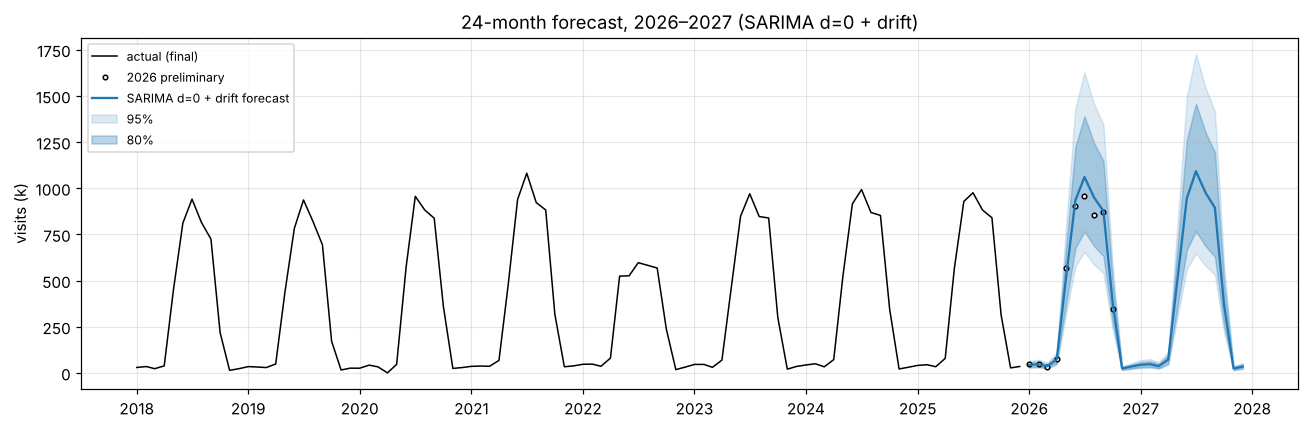

In [28]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(visits["2018":] / 1e3, color="k", lw=1, label="actual (final)")
ax.plot(prelim / 1e3, "o", color="k", ms=3, mfc="white", label="2026 preliminary")
ax.plot(out.forecast / 1e3, color="C0", label=f"{FINAL} forecast")
ax.fill_between(out.index, out.lo95 / 1e3, out.hi95 / 1e3, color="C0", alpha=0.15, label="95%")
ax.fill_between(out.index, out.lo80 / 1e3, out.hi80 / 1e3, color="C0", alpha=0.3, label="80%")
ax.set_ylabel("visits (k)"); ax.legend(fontsize=8); ax.set_title(f"24-month forecast, 2026–2027 ({FINAL})")
fig.tight_layout(); fig.savefig(FIG / "q4_final_forecast.png", dpi=150); plt.show()

## Summary (plain English)
*Filled in from the numbers above — see the final cell output.*

In [29]:
s1 = sc[(sc.period == "2010–2019")].set_index(["h", "model"])
s2 = sc[(sc.period != "2010–2019")].set_index(["h", "model"])
worst = by_m.mean(axis=1).sort_values(ascending=False).index[:3]
MN = dict(enumerate("Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split(), 1))
print(f"""
Q0. Recreation visits rose from about 2.0M a year (1980) to 4.8M (2024–25). The season is
extreme: July is roughly {np.exp(seas[7] - seas[11]):.0f} times November. After a seasonal and a
first difference the log series is stationary (ADF p<0.01, KPSS p≥0.10). The best noise model
is SARIMA{ORDER}{SORDER[:3]}12, chosen by BIC among models whose residuals pass Ljung–Box at
lag 24 (p={best.LB24_p:.2f}); the textbook airline model (0,1,1)(0,1,1)12 leaves autocorrelation.
Residuals are heavy-tailed (odd months such as closures and weather), so p-values for the
shock dummies are approximate. Shock dummies: 1988 fires {coef.loc['D_fire88', '% effect']:.0f}%,
COVID spring 2020 {coef.loc['D_covid20', '% effect']:.0f}%, 2022 flood {coef.loc['D_flood22', '% effect']:.0f}%,
shutdown months {coef.loc['D_shutdown', '% effect']:.0f}%. Over the whole year the 1993 counting change
is not visible ({coef.loc['C_count93', '% effect']:+.0f}%, p={coef.loc['C_count93', 'p']:.2f}); notebook 14
checks it separately for winter, where it matters.

Q4. Over 2010–2019 no model beats "same month last year" by a meaningful margin. Average MASE:
{", ".join(f"{k} {x:.2f}" for k, x in win.items())}. One month ahead the best is
{sc[(sc.period == "2010–2019") & (sc.h == 1)].iloc[0].model} (MAPE {sc[(sc.period == "2010–2019") & (sc.h == 1)].iloc[0]["MAPE %"]:.1f}%),
twelve months ahead {sc[(sc.period == "2010–2019") & (sc.h == 12)].iloc[0].model}
(MAPE {sc[(sc.period == "2010–2019") & (sc.h == 12)].iloc[0]["MAPE %"]:.1f}%). Diebold–Mariano finds no significant
difference between the top two at either horizon (p={dm.p[0]:.2f} at h=1, p={dm.p[1]:.2f} at h=12).
The seasonal pattern is so stable that last year is already an excellent forecast; the
remaining error is in the shoulder months, worst in {", ".join(MN[m] for m in worst)}, whose
size depends on road opening/closing dates, early snow and shutdowns (Oct 2013).
In 2020–2025 errors roughly double for every model (COVID, 2021 record, 2022 flood).
The final 24-month forecast uses {FINAL}; on the preliminary Jan–Oct 2026 data it has a
MAPE of {100 * ((chk.forecast - chk.prelim_2026_actual).abs() / chk.prelim_2026_actual).mean():.1f}% and all
{len(chk)} months fall inside its 95% interval.
""")


Q0. Recreation visits rose from about 2.0M a year (1980) to 4.8M (2024–25). The season is
extreme: July is roughly 66 times November. After a seasonal and a
first difference the log series is stationary (ADF p<0.01, KPSS p≥0.10). The best noise model
is SARIMA(0, 1, 2)(1, 1, 1)12, chosen by BIC among models whose residuals pass Ljung–Box at
lag 24 (p=0.07); the textbook airline model (0,1,1)(0,1,1)12 leaves autocorrelation.
Residuals are heavy-tailed (odd months such as closures and weather), so p-values for the
shock dummies are approximate. Shock dummies: 1988 fires -35%,
COVID spring 2020 -65%, 2022 flood -35%,
shutdown months -36%. Over the whole year the 1993 counting change
is not visible (+2%, p=0.83); notebook 14
checks it separately for winter, where it matters.

Q4. Over 2010–2019 no model beats "same month last year" by a meaningful margin. Average MASE:
Seasonal naive 1.26, SARIMA d=0 + drift 1.28, ETS 1.35, Holt–Winters 1.37, SARIMA 1.48. One month ahead the best is
SARIM

In [30]:
a_all = arch_tab[(arch_tab["sample"] == "all months") & (arch_tab.lags == 12)].p.iloc[0]
a_pre = arch_tab[(arch_tab["sample"] == "1979–2019 only") & (arch_tab.lags == 12)].p.iloc[0]
s10 = scc[scc.period == "2010–2019"]
def encompassers(h):
    e = enc[enc.h == h]
    return [m for m in SINGLE if (e[e.model_1 == m].p >= 0.05).all()]
def encompassed_by_none(h):
    e = enc[enc.h == h]
    return [m for m in SINGLE if (e[e.model_1 == m].p < 0.05).all()]
enc_text = "; ".join(
    f"h = {h}: encompasses all others — {', '.join(encompassers(h)) or 'none'}; "
    f"encompasses none — {', '.join(encompassed_by_none(h)) or 'none'}" for h in H)
d0_rank = list(win.index).index("SARIMA d=0 + drift") + 1 if "SARIMA d=0 + drift" in win.index else None
print(f"""
Extensions (syllabus topics)
Roots (Q0.7). All AR and MA roots lie outside the unit circle, so the d = 1 model is stationary and
invertible, but the smallest MA root is {roots.modulus.min():.3f}: the MA(2) nearly cancels the first difference
(θ(1) = {ma_nonseas.sum():.3f}). This is the classic sign of over-differencing.

ARCH (Q0.8). Residual variance is not constant over the full sample (ARCH-LM p = {a_all:.3f}), but the effect
disappears for 1979–2019 (p = {a_pre:.2f}): what looks like volatility clustering is the 2020–22
run of shocks (COVID closure, record rebound, flood), not persistent volatility.

d = 0 alternative (Q0.9). SARIMA{ORDER0}{SORDER0[:3]}12 with drift passes Ljung–Box (p = {best0.LB24_p:.2f}) and has a fixed
long-run growth of {100 * (np.exp(mu12) - 1):+.1f}% a year. Shock estimates are almost identical to the d = 1 model.

Forecast function (Q0.10). Under d = 1 a shock permanently changes yearly growth (ψ∞ = {lim1:.4f});
under d = 0 it fades to zero. Ten years ahead from 2019 the d = 1 model projects {g1:+.1f}%/yr and the
d = 0 model {g0:+.1f}%/yr (actual 1995–2019: {gh:+.1f}%/yr) — the mechanism behind SARIMA's overshooting.
In the rolling test (2010–19) the d = 0 model ranks {d0_rank} of {len(win)} by average MASE
({win.get('SARIMA d=0 + drift', float('nan')):.2f} vs {win['SARIMA']:.2f} for d = 1).

Combination (Q4b). Best 2010–19 MASE at h = 1: {combo_vs.best_combo[0]} {combo_vs.combo_MASE[0]:.2f} vs best single
{combo_vs.best_single[0]} {combo_vs.single_MASE[0]:.2f} (DM p = {combo_vs.p[0]:.2f}); at h = 12: {combo_vs.best_combo[1]}
{combo_vs.combo_MASE[1]:.2f} vs {combo_vs.best_single[1]} {combo_vs.single_MASE[1]:.2f} (DM p = {combo_vs.p[1]:.2f}).
Encompassing (log errors, 2010–19): {enc_text}
Combining works because no single model contains all the information in the others; the gains over
the best single model (about 3–4% lower MASE) are real in sample but not statistically significant.
""")


Extensions (syllabus topics)
Roots (Q0.7). All AR and MA roots lie outside the unit circle, so the d = 1 model is stationary and
invertible, but the smallest MA root is 1.015: the MA(2) nearly cancels the first difference
(θ(1) = 0.064). This is the classic sign of over-differencing.

ARCH (Q0.8). Residual variance is not constant over the full sample (ARCH-LM p = 0.002), but the effect
disappears for 1979–2019 (p = 0.23): what looks like volatility clustering is the 2020–22
run of shocks (COVID closure, record rebound, flood), not persistent volatility.

d = 0 alternative (Q0.9). SARIMA(1, 0, 2)(1, 1, 1)12 with drift passes Ljung–Box (p = 0.06) and has a fixed
long-run growth of +1.6% a year. Shock estimates are almost identical to the d = 1 model.

Forecast function (Q0.10). Under d = 1 a shock permanently changes yearly growth (ψ∞ = 0.0131);
under d = 0 it fades to zero. Ten years ahead from 2019 the d = 1 model projects +3.5%/yr and the
d = 0 model +0.8%/yr (actual 1995–2019: +2.8